# Notebook 17: Client Fairness Auditing & Inequality Ablation (Gini Coefficient)

## 1. Fairness Metric
Across client-level NDCG@10 values $\{x_1, \dots, x_K\}$, inequality is measured by the Gini coefficient:
$$G = \frac{\sum_{i=1}^K \sum_{j=1}^K |x_i - x_j|}{2 K^2 \bar{x}} \in [0, 1]$$
Lower $G$ indicates more equitable recommendation quality across minority-niche and majority-niche readers.

             Regime  Gini_Inequality  NDCG@10
Isolated Local-Only           0.3786   0.0898
   FedAvg (Non-IID)           0.3528   0.0500
  FedProx (mu=0.01)           0.3230   0.0742


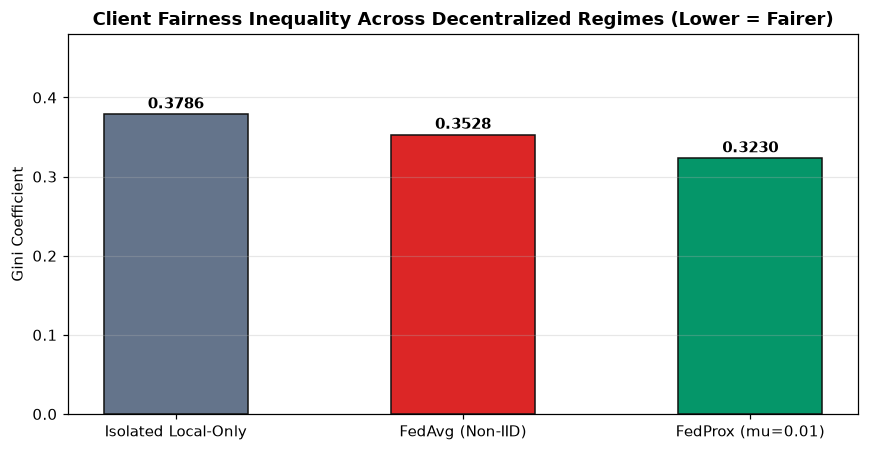

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
with open(os.path.join(ARTIFACTS_DIR, "federated_benchmark.json"), "r") as f:
    bench = json.load(f)

fairness_df = pd.DataFrame([
    {"Regime": "Isolated Local-Only", "Gini_Inequality": bench["isolated_local"]["gini_inequality"], "NDCG@10": bench["isolated_local"]["ndcg10"]},
    {"Regime": "FedAvg (Non-IID)", "Gini_Inequality": bench["fedavg_non_iid"]["gini_inequality"], "NDCG@10": bench["fedavg_non_iid"]["ndcg10"]},
    {"Regime": "FedProx (mu=0.01)", "Gini_Inequality": bench["fedprox_non_iid"]["gini_inequality"], "NDCG@10": bench["fedprox_non_iid"]["ndcg10"]},
])
print(fairness_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(fairness_df["Regime"], fairness_df["Gini_Inequality"], color=["#64748b", "#dc2626", "#059669"], edgecolor="#111110", width=0.5)
ax.set_title("Client Fairness Inequality Across Decentralized Regimes (Lower = Fairer)", fontweight="bold")
ax.set_ylabel("Gini Coefficient")
ax.set_ylim(0, 0.48)
for b in bars:
    h = b.get_height()
    ax.annotate(f"{h:.4f}", (b.get_x() + b.get_width() / 2, h), xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()